# Monte Carlo Simulation and Value at Risk for Goldman Sachs

In [1]:
import yfinance as yf
import pandas as pd

In [2]:
# Download 3 years of daily historical data from Goldman sachs
df = yf.download("GS", period = "3y")

# Save it as a CSV file in your current directory
df.to_csv("gs_historical.csv")
print("Saved successfully as 'gs_historical.csv'!")

[*********************100%***********************]  1 of 1 completed

Saved successfully as 'gs_historical.csv'!


### Data inspection

In [3]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,GS,GS,GS,GS,GS
Date,,,,,
2023-11-06,302.965057,307.632381,301.272099,305.537235,2087600
2023-11-07,303.002533,305.284758,300.514532,301.300212,1505000
2023-11-08,303.573120,305.537334,302.740685,303.002578,1484400
2023-11-09,300.037537,305.527963,298.989963,304.919999,1787900
2023-11-10,304.461670,304.976094,300.851253,302.413279,1781400


In [4]:
df.columns

MultiIndex([( 'Close', 'GS'),
            (  'High', 'GS'),
            (   'Low', 'GS'),
            (  'Open', 'GS'),
            ('Volume', 'GS')],
           names=['Price', 'Ticker'])

In [5]:
df.index.name

'Date'

In [6]:
#Remove the second-level index of the header
df.columns = df.columns.droplevel(1)
df.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2023-11-06,302.965057,307.632381,301.272099,305.537235,2087600
2023-11-07,303.002533,305.284758,300.514532,301.300212,1505000
2023-11-08,303.573120,305.537334,302.740685,303.002578,1484400
2023-11-09,300.037537,305.527963,298.989963,304.919999,1787900
2023-11-10,304.461670,304.976094,300.851253,302.413279,1781400


In [7]:
#Remove the header's row name
df.columns.name = None
df.head(10)

,Close,High,Low,Open,Volume
Date,,,,,
2023-11-06,302.965057,307.632381,301.272099,305.537235,2087600
2023-11-07,303.002533,305.284758,300.514532,301.300212,1505000
2023-11-08,303.573120,305.537334,302.740685,303.002578,1484400
2023-11-09,300.037537,305.527963,298.989963,304.919999,1787900
2023-11-10,304.461670,304.976094,300.851253,302.413279,1781400
2023-11-13,305.771118,307.464076,302.609674,303.198941,1403300
2023-11-14,316.817444,319.679574,310.971586,311.963041,3592700
2023-11-15,315.769897,319.024853,313.656026,317.921162,2534500
2023-11-16,314.899994,317.780820,313.347331,315.919508,1620400


In [8]:
df.dtypes

Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

In [9]:
df.shape

(753, 5)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 753 entries, 2023-11-06 to 2026-11-05
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   753 non-null    float64
 1   High    753 non-null    float64
 2   Low     753 non-null    float64
 3   Open    753 non-null    float64
 4   Volume  753 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 35.3 KB


In [11]:
df.isnull().sum()

Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

In [12]:
#Check if there's no duplicates
df.index.duplicated().sum()


np.int64(0)

In [13]:
#Check if the stock data date is arranged from the past dates to present
df.index.is_monotonic_increasing


True

In [14]:
df.tail()

,Close,High,Low,Open,Volume
Date,,,,,
2026-10-30,894.549988,906.890015,879.500000,905.099976,2153100
2026-11-02,898.719971,916.950012,896.969971,908.799988,1859200
2026-11-03,896.090027,903.150024,892.099976,903.000000,1434000
2026-11-04,928.000000,933.340027,899.599976,920.309998,2819700
2026-11-05,868.950012,934.000000,854.515015,932.320007,3863500


In [15]:
#Remove the last row since the data was downloaded before today's market close so the volume and the closing price would be live not the final.
df = df[df.index < "2026-10-26"].copy()
df.tail(3)

,Close,High,Low,Open,Volume
Date,,,,,
2026-10-21,904.719971,906.479980,888.270020,900.000000,2503200
2026-10-22,891.299988,906.349976,881.000000,884.919983,2032900
2026-10-23,875.679993,886.750000,870.820007,880.070007,1781600


In [16]:
df.shape

(744, 5)

#### Data validation

In [17]:
#Condition 1
(df["High"] >= df["Low"]).all()


np.True_

In [18]:
#Condition 2
((df["Close"] <= df["High"]) & (df["Close"] >= df["Low"])).all()


np.True_

In [19]:
#Condition 3
(df["Close"] > 0).all()


np.True_

In [20]:
#Condition 4
(df["Volume"] > 0).all()

np.True_

In [21]:
df["Close"].describe()

count     744.000000
mean      654.832584
std       226.718044
min       300.037537
25%       464.443123
50%       599.374603
75%       875.282059
max      1146.455078
Name: Close, dtype: float64

In [22]:
# Save the cleaned data as a CSV file
df.to_csv("gs_clean.csv")

#upload the file again just to check
check = pd.read_csv("gs_clean.csv", index_col=0, parse_dates=True)
check.shape


(744, 5)

In [23]:
df["Prev Close"] = df["Close"].shift(1)
df[["Close", "Prev Close"]].head()

,Close,Prev Close
Date,,
2023-11-06,302.965057,NaN
2023-11-07,303.002533,302.965057
2023-11-08,303.573120,303.002533
2023-11-09,300.037537,303.573120
2023-11-10,304.461670,300.037537


In [24]:
import numpy as np
df["Log Return"] = np.log(df["Close"] / df["Prev Close"])
df[["Close", "Prev Close", "Log Return"]].head()

,Close,Prev Close,Log Return
Date,,,
2023-11-06,302.965057,NaN,NaN
2023-11-07,303.002533,302.965057,0.000124
2023-11-08,303.573120,303.002533,0.001881
2023-11-09,300.037537,303.573120,-0.011715
2023-11-10,304.461670,300.037537,0.014638


In [25]:
returns = df["Log Return"].dropna()
returns.shape

(743,)

In [26]:
total_daily_log_returns = returns.sum()
# np.log(df["Close"].iloc[-1] / df["Close"].iloc[0])

print("Total log returns: ",total_daily_log_returns)

Total log returns:  1.0613832423734857


In [27]:
avg_daily_return = returns.mean()
volatility = returns.std()
annual_volatility = volatility * np.sqrt(252)

print("Average daily Return: ", round(avg_daily_return, 6))
print("Daily Volatility: ", round(volatility, 4))
print(f"Annual Volatility: {annual_volatility * 100:.2f}%")

Average daily Return:  0.001429
Daily Volatility:  0.0186
Annual Volatility: 29.60%


In [28]:
returns.describe()

count    743.000000
mean       0.001429
std        0.018644
min       -0.096638
25%       -0.008220
50%        0.001225
75%        0.011360
max        0.123083
Name: Log Return, dtype: float64

In [29]:
print(f"Min Return Date: {returns.idxmin()}, {round(returns.min()*100,2)}%")

print(f"Max Return Date: {returns.idxmax()} : {round(returns.max()*100, 2)}%")

Min Return Date: 2025-04-03 00:00:00, -9.66%
Max Return Date: 2024-11-06 00:00:00 : 12.31%


In [30]:
num_simulations = 10000
num_days = 30

#Generate a grid of random shocks: 30rows by 10,000columns
np.random.seed(42)
random_shocks = np.random.normal(0,1, size = (num_days, num_simulations))

random_shocks.shape

(30, 10000)

In [31]:
#Scale the standard normal random shocks by Goldman Sachs' daily volatility
shock_component = random_shocks * volatility


#The drift component for our daily returns matrix
drift = avg_daily_return

#Total daily log return for all 30 days and 10,000 paths simulatneously 
daily_returns_sim = drift + shock_component

In [32]:
# Get the last closing price from the data
last_price = df['Close'].iloc[-1]
print(f"Last Price: ${last_price:2f}")

Last Price: $875.679993


In [33]:
#Convert the log returns into cumulative price paths starting from the last price using "np.cumsum"
#and np.exp converts the total simulated days price for each scinero/column from log space into a normal price multiplier

price_paths = last_price * np.exp(np.cumsum(daily_returns_sim, axis =0))
price_paths.shape

(30, 10000)

In [34]:
#Adding a new row to the top of the matrix to contain the last day closing price
start_row = np.full((1, num_simulations), last_price)

In [35]:
#We stack 'start_row' (Day 0) on top of 'price_paths' (Day 1-30)
price_paths = np.vstack([start_row, price_paths])   
#np.vstack() means vertical stack and it adds the two arrays on top of each other

price_paths.shape

(31, 10000)

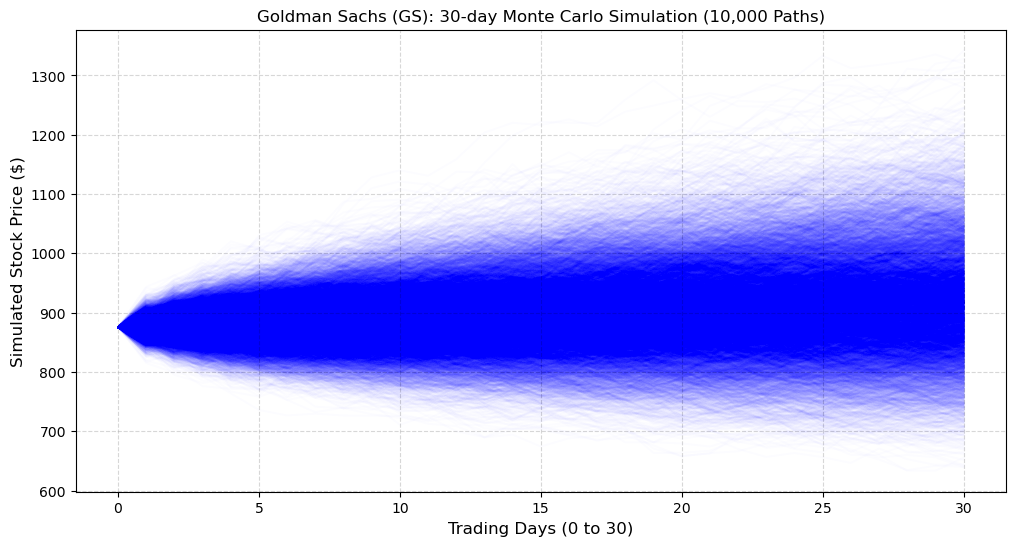

In [36]:
import matplotlib.pyplot as plt

#set up the figure size for a clean, professional financial chart
plt.figure(figsize = (12,6))

#plot all 10,000 paths with high transparency (alpha) so the overlapping density shows trends
plt.plot(price_paths, 'b', alpha = 0.01)   #0.01 alpha means 97% transparency

#Add clear labels, title, and a grid for readability
plt.title("Goldman Sachs (GS): 30-day Monte Carlo Simulation (10,000 Paths)")
plt.xlabel("Trading Days (0 to 30)", fontsize = 12)
plt.ylabel("Simulated Stock Price ($)", fontsize = 12)
plt.grid(True, linestyle = '--', alpha = 0.5)

#Display the plot
plt.show()

## Value at Risk (VaR)

In [37]:
#1. Isolate all 10,000 simulated prices on Day 30
final_prices = price_paths[-1,:]
print(final_prices)

[1000.58182576  987.99330887  851.5386447  ...  781.00293395  877.54329621
  809.77264683]


In [39]:
#2. Calculate the dollar change from our starting price for each of the 10,000 paths
price_changes = final_prices - last_price

#3. Find the 5th percentile of those changes for a 95% confidence level
confidence_level = 0.95
var_dollar = np.percentile(price_changes, (1-confidence_level)*100)   #np.percentile(price_changes, percentile_num)
var_percent = var_dollar / last_price *100


print(f"30-Day Dollar VaR (95% Confidence): ${abs(var_dollar): .2f} per share")

30-Day Dollar VaR (95% Confidence): $ 103.60 per share
